## PennyLane Quantum Computing Framework: Introduction Exercises

In [50]:
#Libraries
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

In [2]:
import pennylane as qp
qml = qp

### Codercise I.1.1 Normalization of Quantum States

In [9]:
# Here are the vector representations of |0> and |1>, for convenience
ket_0 = np.array([1, 0])
ket_1 = np.array([0, 1])


def normalize_state(alpha, beta):
    """Compute a normalized quantum state given arbitrary amplitudes.

    Args:
        alpha (complex): The amplitude associated with the |0> state.
        beta (complex): The amplitude associated with the |1> state.

    Returns:
        np.array[complex]: A vector (numpy array) with 2 elements that represents
        a normalized quantum state.
    """

    # CREATE A VECTOR [a', b'] BASED ON alpha AND beta SUCH THAT |a'|^2 + |b'|^2 = 1
    mod_alpha = alpha*alpha.conjugate()
    mod_beta = beta*beta.conjugate()
    norm = np.sqrt(mod_alpha + mod_beta)
    normalized_vector = (alpha/norm) * ket_0 + (beta/norm) * ket_1

    # RETURN A VECTOR
    return normalized_vector

### Codercise I.1.2 Inner Product and Orthonormal Basis

In [5]:
def inner_product(state_1, state_2):
    """Compute the inner product between two states.

    Args:
        state_1 (np.array[complex]): A normalized quantum state vector
        state_2 (np.array[complex]): A second normalized quantum state vector

    Returns:
        complex: The value of the inner product <state_1 | state_2>.
    """

    state_1_conj = np.array([state_1[0].conjugate(), state_1[1].conjugate()])
    inner_prod = np.dot(state_1_conj, state_2)
    return inner_prod


# Test your results with this code
ket_0 = np.array([1, 0])
ket_1 = np.array([0, 1])

print(f"<0|0> = {inner_product(ket_0, ket_0)}")
print(f"<0|1> = {inner_product(ket_0, ket_1)}")
print(f"<1|0> = {inner_product(ket_1, ket_0)}")
print(f"<1|1> = {inner_product(ket_1, ket_1)}")

<0|0> = 1
<0|1> = 0
<1|0> = 0
<1|1> = 1


### Codercise I.1.3 Sampling Measurement Outcomes

In [6]:
def measure_state(state, num_meas):
    """Simulate a quantum measurement process.

    Args:
        state (np.array[complex]): A normalized qubit state vector.
        num_meas (int): The number of measurements to take

    Returns:
        np.array[int]: A set of num_meas samples, 0 or 1, chosen according to the probability
        distribution defined by the input state.
    """

    # COMPUTE THE MEASUREMENT OUTCOME PROBABILITIES
    rng = np.random.default_rng()
    prob_one = state[0]*state[0].conjugate()
    measurements = [] 

    for i in range(num_meas):
        prob = rng.random()
        if prob <= prob_one:
            measurements.append(0)
        else:
            measurements.append(1)

    # RETURN A LIST OF SAMPLE MEASUREMENT OUTCOMES
    return np.array(measurements)

### Codercise I.1.4 Applying a Quantum Operation

In [7]:
U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def apply_u(state):
    """Apply a quantum operation.

    Args:
        state (np.array[complex]): A normalized quantum state vector.

    Returns:
        np.array[complex]: The output state after applying U.
    """

    return np.dot(U, state)
   

### Codercise I.1.5 A Simple Quantum Algorithm

In [8]:
U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def initialize_state():
    """Prepare a qubit in state |0>.

    Returns:
        np.array[float]: the vector representation of state |0>.
    """

    # PREPARE THE STATE |0>
    return np.array([1,0])


def quantum_algorithm():
    """Use the functions above to implement the quantum algorithm described above.

    Try and do so using three lines of code or less!

    Returns:
        np.array[int]: the measurement results after running the algorithm 100 times
    """

    # PREPARE THE STATE, APPLY U, THEN TAKE 100 MEASUREMENT SAMPLES
    state = initialize_state()
    state_prime = apply_u(state)
    return measure_state(state_prime, 100)

In [10]:
print("Measurements:",quantum_algorithm())

Measurements: [1 0 1 0 1 1 1 1 0 0 1 0 0 0 1 1 0 1 0 0 1 0 1 0 1 1 1 1 1 0 1 1 0 0 1 0 0
 1 0 1 0 0 0 1 1 1 1 0 1 1 0 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 0 1 0 0 1 0 0 1
 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 0 1 1]


### Codercise I.2.1 Order of Operations

In [3]:
#Quantum Circuit

def my_circuit(theta, phi):

    qp.CNOT(wires=[0, 1])
    qp.RX(theta, wires=2)
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[2, 0])
    qp.RY(phi, wires=1)

    # This is the measurement; we return the probabilities of all possible output states
    # You'll learn more about what types of measurements are available in a later node
    return qp.probs(wires=[0, 1, 2])

### Codercise I.2.2 Building a QNode

In [4]:
# This creates a device with three wires on which PennyLane can run computations
dev = qp.device("default.qubit", wires=3)


def my_circuit(theta, phi, omega):

    # IMPLEMENT THE CIRCUIT BY ADDING THE GATES

    # Here are two examples, so you can see the format:
    # qp.CNOT(wires=[0, 1])
    # qp.RX(theta, wires=0)

    qp.RX(theta, wires=[0])
    qp.RY(phi, wires=[1])
    qp.RZ(omega, wires=[2])
    qp.CNOT(wires = [0,1])
    qp.CNOT(wires = [1,2])
    qp.CNOT(wires = [2,0])
    return qp.probs(wires=[0, 1, 2])


# This creates a QNode, binding the function and device
my_qnode = qp.QNode(my_circuit, dev)

# We set up some values for the input parameters
theta, phi, omega = 0.1, 0.2, 0.3

# Now we can execute the QNode by calling it like we would a regular function
my_qnode(theta, phi, omega)

array([9.87560268e-01, 0.00000000e+00, 0.00000000e+00, 2.47302134e-03,
       2.48960206e-05, 0.00000000e+00, 0.00000000e+00, 9.94181506e-03])

### Codercise I.2.3 - The QNode Decorator

In [6]:
dev = qp.device("default.qubit", wires=3)
@qp.qnode(dev)

# DECORATE THE FUNCTION BELOW TO TURN IT INTO A QNODE


def my_circuit(theta, phi, omega):
    qp.RX(theta, wires=0)
    qp.RY(phi, wires=1)
    qp.RZ(omega, wires=2)
    qp.CNOT(wires=[0, 1])
    qp.CNOT(wires=[1, 2])
    qp.CNOT(wires=[2, 0])
    return qp.probs(wires=[0, 1, 2])


theta, phi, omega = 0.1, 0.2, 0.3

my_circuit(0.1, 0.2, 0.3)

# RUN THE QNODE WITH THE PROVIDED PARAMETERS

array([9.87560268e-01, 0.00000000e+00, 0.00000000e+00, 2.47302134e-03,
       2.48960206e-05, 0.00000000e+00, 0.00000000e+00, 9.94181506e-03])

### Codercise 1.2.4 Circuit Depth

In [ ]:
dev = qp.device("default.qubit", wires=3)


@qp.qnode(dev)
def my_circuit(theta, phi, omega):
    qp.RX(theta, wires=0)
    qp.RY(phi, wires=1)
    qp.RZ(omega, wires=2)
    qp.CNOT(wires=[0, 1])
    qp.CNOT(wires=[1, 2])
    qp.CNOT(wires=[2, 0])
    return qp.probs(wires=[0, 1, 2])


# FILL IN THE CORRECT CIRCUIT DEPTH
depth = 4

### Codercise I.3.1 Unitaries in PennyLane

In [16]:
dev = qp.device("default.qubit", wires=1)

U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


@qp.qnode(dev)
def apply_u():

    # USE QubitUnitary TO APPLY U TO THE QUBIT

    qp.QubitUnitary(U, wires = 0)

    # Return the state
    return qp.state()

apply_u()

array([0.70710678+0.j, 0.70710678+0.j])

### Codercise I.3.2 Parametrized Unitaries

In [18]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_u_as_rot(phi, theta, omega):

    # APPLY A ROT GATE USING THE PROVIDED INPUT PARAMETERS
    qp.Rot(phi, theta, omega, wires=0)

    # RETURN THE QUANTUM STATE VECTOR

    return qp.state()

apply_u_as_rot(np.pi, np.pi/4, np.pi/6)

array([-0.23911762-0.8923991j ,  0.09904576-0.36964381j])

### Codercise I.4.1 Flipping Bits

In [27]:
dev = qp.device("default.qubit", wires=1)

U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


@qp.qnode(dev)
def varied_initial_state(state):
    """Complete the function such that we can apply the operation U to
    either |0> or |1> depending on the input argument flag.

    Args:
        state (int): Either 0 or 1. If 1, prepare the qubit in state |1>,
            otherwise, leave it in state 0.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """

    # KEEP THE QUBIT IN |0> OR CHANGE IT TO |1> DEPENDING ON THE state PARAMETER
    if(state == 1):
        qp.PauliX(wires = 0)

    # APPLY U TO THE STATE
    qp.QubitUnitary(U, wires=0)

    return qp.state()

print(varied_initial_state(0))
print(varied_initial_state(1))

[0.70710678+0.j 0.70710678+0.j]
[ 0.70710678+0.j -0.70710678+0.j]


### Codercise I.4.2 Uniform Superposition

In [28]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_hadamard():

    # APPLY THE HADAMARD GATE
    qp.Hadamard(wires=0)

    # RETURN THE STATE
    return qp.state()

### Codercise I.4.3 Combining X and H

In [31]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_hadamard_to_state(state):
    """Complete the function such that we can apply the Hadamard to
    either |0> or |1> depending on the input argument flag.

    Args:
        state (int): Either 0 or 1. If 1, prepare the qubit in state |1>,
            otherwise, leave it in state 0.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """

    # KEEP THE QUBIT IN |0> OR CHANGE IT TO |1> DEPENDING ON state
    if(state == 1):
        qp.PauliX(wires = 0)

    # APPLY THE HADAMARD
    qp.Hadamard(wires = 0)

    # RETURN THE STATE

    return qp.state()


print(apply_hadamard_to_state(0))
print(apply_hadamard_to_state(1))

[0.70710678+0.j 0.70710678+0.j]
[ 0.70710678+0.j -0.70710678+0.j]


### I.4.4 A QNode with X and H

In [32]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)

def apply_hxh(state):
    if (state ==1):
        qp.PauliX(wires = 0)

    qp.Hadamard(wires = 0)
    qp.PauliX(wires = 0)
    qp.Hadamard(wires = 0)
    return qp.state()

print(apply_hxh(0))
print(apply_hxh(1))


[1.+0.j 0.+0.j]
[ 0.+0.j -1.+0.j]


### Codercise I.5.1 The Pauli Z Gate

In [35]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_z_to_plus():
    """Write a circuit that applies PauliZ to the |+> state and returns
    the state.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """

    # CREATE THE |+> STATE
    qp.Hadamard(wires = 0)

    # APPLY PAULI Z
    qp.PauliZ(wires = 0)

    # RETURN THE STATE
    return qp.state()


print(apply_z_to_plus())

[ 0.70710678+0.j -0.70710678+0.j]


### Codercise I.5.2 The Z Rotation

In [38]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def fake_z():
    """Use RZ to produce the same action as Pauli Z on the |+> state.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """


    # CREATE THE |+> STATE
    qp.Hadamard(wires = 0)

    # APPLY RZ
    qp.RZ(np.pi, wires = 0)

    # RETURN THE STATE
    return qp.state()

print(fake_z())

[4.32978028e-17-0.70710678j 4.32978028e-17+0.70710678j]


### Codercise I.5.3 The S and T Gates

In [40]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def many_rotations():
    """Implement the circuit depicted above and return the quantum state.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """

    # IMPLEMENT THE CIRCUIT
    qp.Hadamard(wires = 0)
    qp.S(wires=0)
    qp.adjoint(qp.T)(wires = 0)
    qp.RZ(0.3, wires = 0)
    qp.adjoint(qp.S)(wires = 0)


    # RETURN THE STATE

    return qp.state()

### Codercise I.6.2 Applying RX

In [44]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_rx_pi(state):
    """Apply an RX gate with an angle of pi to a particular basis state.

    Args:
        state (int): Either 0 or 1. If 1, initialize the qubit to state |1>
            before applying other operations.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """
    if state == 1:
        qp.PauliX(wires=0)

    # APPLY RX(pi) AND RETURN THE STATE
    qp.RX(np.pi, wires=0)

    return qp.state()


print(apply_rx_pi(0))
print(apply_rx_pi(1))

[6.123234e-17+0.j 0.000000e+00-1.j]
[0.000000e+00-1.j 6.123234e-17+0.j]


### Codercise 1.6.2 Plotting RX

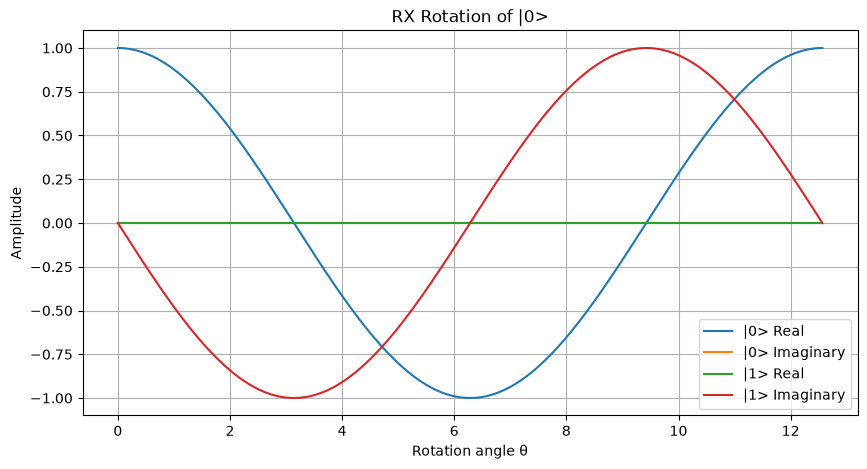

In [51]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_rx(theta, state):
    """Apply an RX gate with an angle of theta to a particular basis state.

    Args:
        theta (float): A rotation angle.
        state (int): Either 0 or 1. If 1, initialize the qubit to state |1>
            before applying other operations.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """
    if state == 1:
        qp.PauliX(wires=0)

    # APPLY RX(theta) AND RETURN THE STATE
    qp.RX(theta, wires = 0)

    return qp.state()


# Code for plotting
angles = np.linspace(0, 4 * np.pi, 200)
output_states = np.array([apply_rx(t, 0) for t in angles])

plt.figure(figsize=(10, 5))

plt.plot(angles, output_states[:, 0].real, label="|0> Real")
plt.plot(angles, output_states[:, 0].imag, label="|0> Imaginary")
plt.plot(angles, output_states[:, 1].real, label="|1> Real")
plt.plot(angles, output_states[:, 1].imag, label="|1> Imaginary")

plt.xlabel("Rotation angle θ")
plt.ylabel("Amplitude")
plt.title("RX Rotation of |0>")
plt.legend()
plt.grid(True)
plt.show()

### Codercise I.6.3 Plotting RY

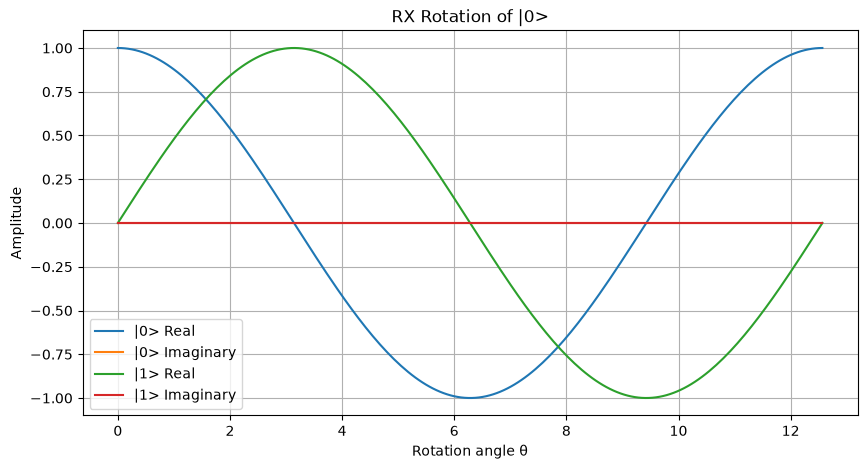

In [52]:
dev = qp.device("default.qubit", wires=1)


@qp.qnode(dev)
def apply_ry(theta, state):
    """Apply an RY gate with an angle of theta to a particular basis state.

    Args:
        theta (float): A rotation angle.
        state (int): Either 0 or 1. If 1, initialize the qubit to state |1>
            before applying other operations.

    Returns:
        np.array[complex]: The state of the qubit after the operations.
    """
    if state == 1:
        qp.PauliX(wires=0)

    ##################

    # APPLY RY(theta) AND RETURN THE STATE
    qp.RY(theta, wires = 0)

    return qp.state()

# Code for plotting
angles = np.linspace(0, 4 * np.pi, 200)
output_states = np.array([apply_ry(t, 0) for t in angles])

plt.figure(figsize=(10, 5))

plt.plot(angles, output_states[:, 0].real, label="|0> Real")
plt.plot(angles, output_states[:, 0].imag, label="|0> Imaginary")
plt.plot(angles, output_states[:, 1].real, label="|1> Real")
plt.plot(angles, output_states[:, 1].imag, label="|1> Imaginary")

plt.xlabel("Rotation angle θ")
plt.ylabel("Amplitude")
plt.title("RX Rotation of |0>")
plt.legend()
plt.grid(True)
plt.show()